In [3]:
from google.colab import drive
from pathlib import Path
import zipfile

drive.mount("/content/drive")

DRIVE_DATASET_DIR = Path("/content/drive/MyDrive/final_year_project/Grapes")
RAW_DIR = Path("/content/grape_raw")

RAW_DIR.mkdir(parents=True, exist_ok=True)

zip_files = list(DRIVE_DATASET_DIR.glob("*.zip"))

if not zip_files:
    raise FileNotFoundError(
        f"No ZIP files found in: {DRIVE_DATASET_DIR}\n"
        "Update DRIVE_DATASET_DIR to the folder where your ZIP files are stored."
    )

for zip_path in zip_files:
    output_folder = RAW_DIR / zip_path.stem
    output_folder.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_file:
        zip_file.extractall(output_folder)

    print(f"Extracted: {zip_path.name}")
    print(f"Saved to: {output_folder}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracted: Resized 1024 × 1024.zip
Saved to: /content/grape_raw/Resized 1024 × 1024


In [4]:
from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for folder in sorted(RAW_DIR.rglob("*")):
    if not folder.is_dir():
        continue

    image_count = sum(
        1 for file_path in folder.rglob("*")
        if file_path.suffix.lower() in IMAGE_EXTENSIONS
    )

    if image_count > 0:
        print(f"{folder.relative_to(RAW_DIR)}  -->  {image_count} images")

Resized 1024 × 1024  -->  5267 images
Resized 1024 × 1024/resized  -->  5267 images
Resized 1024 × 1024/resized/Downy Mildew  -->  1006 images
Resized 1024 × 1024/resized/Erineum Mite  -->  1013 images
Resized 1024 × 1024/resized/Esca Complex  -->  1000 images
Resized 1024 × 1024/resized/Healthy  -->  1122 images
Resized 1024 × 1024/resized/Powdery Mildew  -->  1126 images


In [5]:
for folder in sorted(DRIVE_DATASET_DIR.iterdir()):
    if not folder.is_dir():
        continue

    image_count = sum(
        1
        for file_path in folder.rglob("*")
        if file_path.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"{folder.name}  -->  {image_count} images")


fieldvitis  -->  556 images


In [6]:
FIELDVITIS_DIR = DRIVE_DATASET_DIR / "fieldvitis"

for folder in sorted(FIELDVITIS_DIR.iterdir()):
    if not folder.is_dir():
        continue

    image_count = sum(
        1
        for file_path in folder.rglob("*")
        if file_path.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"{folder.name}  -->  {image_count} images")

Black_rot  -->  39 images
Esca  -->  201 images
Healthy  -->  158 images
Leaf_blight  -->  158 images


In [8]:
from pathlib import Path
import pandas as pd

RAW_DIR = Path("/content/grape_raw")
PORTUGUESE_DIR = RAW_DIR / "Resized 1024 × 1024" / "resized"

DRIVE_DATASET_DIR = Path("/content/drive/MyDrive/grape_datasets")
FIELDVITIS_DIR = DRIVE_DATASET_DIR / "fieldvitis"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

CLASS_FOLDERS = {
    PORTUGUESE_DIR / "Healthy": ("healthy", "portuguese_rgb"),
    PORTUGUESE_DIR / "Downy Mildew": ("downy_mildew", "portuguese_rgb"),
    PORTUGUESE_DIR / "Powdery Mildew": ("powdery_mildew", "portuguese_rgb"),
    PORTUGUESE_DIR / "Esca Complex": ("esca_complex", "portuguese_rgb"),
    PORTUGUESE_DIR / "Erineum Mite": ("erineum_mite", "portuguese_rgb"),

    FIELDVITIS_DIR / "Healthy": ("healthy", "fieldvitis"),
    FIELDVITIS_DIR / "Esca": ("esca_complex", "fieldvitis"),
}

rows = []

for folder_path, (label, source) in CLASS_FOLDERS.items():
    if not folder_path.exists():
        print(f"Folder not found: {folder_path}")
        continue

    for image_path in folder_path.rglob("*"):
        if image_path.suffix.lower() in IMAGE_EXTENSIONS:
            rows.append({
                "image_path": str(image_path),
                "label": label,
                "source": source,
                "early_like": 0,
            })

manifest = pd.DataFrame(rows)

print("Total images:", len(manifest))

display(
    manifest.groupby(["source", "label"])
    .size()
    .reset_index(name="images")
    .sort_values(["label", "source"])
)

Folder not found: /content/drive/MyDrive/grape_datasets/fieldvitis/Healthy
Folder not found: /content/drive/MyDrive/grape_datasets/fieldvitis/Esca
Total images: 5267


,source,label,images
0,portuguese_rgb,downy_mildew,1006
1,portuguese_rgb,erineum_mite,1013
2,portuguese_rgb,esca_complex,1000
3,portuguese_rgb,healthy,1122
4,portuguese_rgb,powdery_mildew,1126


In [9]:
CLASS_FOLDERS = {
    PORTUGUESE_DIR / "Healthy": ("healthy", "portuguese_rgb"),
    PORTUGUESE_DIR / "Downy Mildew": ("downy_mildew", "portuguese_rgb"),
    PORTUGUESE_DIR / "Powdery Mildew": ("powdery_mildew", "portuguese_rgb"),
    PORTUGUESE_DIR / "Esca Complex": ("esca_complex", "portuguese_rgb"),
    PORTUGUESE_DIR / "Erineum Mite": ("erineum_mite", "portuguese_rgb"),

    FIELDVITIS_DIR / "Healthy": ("healthy", "fieldvitis"),
    FIELDVITIS_DIR / "Esca": ("esca_complex", "fieldvitis"),
}

rows = []

for folder_path, (label, source) in CLASS_FOLDERS.items():
    for image_path in folder_path.rglob("*"):
        if image_path.suffix.lower() in IMAGE_EXTENSIONS:
            rows.append({
                "image_path": str(image_path),
                "label": label,
                "source": source,
                "early_like": 0,
            })

manifest = pd.DataFrame(rows)

print("Total images:", len(manifest))

display(
    manifest.groupby(["source", "label"])
    .size()
    .reset_index(name="images")
    .sort_values(["label", "source"])
)

Total images: 5267


,source,label,images
0,portuguese_rgb,downy_mildew,1006
1,portuguese_rgb,erineum_mite,1013
2,portuguese_rgb,esca_complex,1000
3,portuguese_rgb,healthy,1122
4,portuguese_rgb,powdery_mildew,1126


In [10]:
from pathlib import Path
import pandas as pd

RAW_DIR = Path("/content/grape_raw")
PORTUGUESE_DIR = RAW_DIR / "Resized 1024 × 1024" / "resized"

GRAPES_DRIVE_DIR = Path("/content/drive/MyDrive/final_year_project/Grapes")
FIELDVITIS_DIR = GRAPES_DRIVE_DIR / "fieldvitis"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

CLASS_FOLDERS = {
    PORTUGUESE_DIR / "Healthy": ("healthy", "portuguese_rgb"),
    PORTUGUESE_DIR / "Downy Mildew": ("downy_mildew", "portuguese_rgb"),
    PORTUGUESE_DIR / "Powdery Mildew": ("powdery_mildew", "portuguese_rgb"),
    PORTUGUESE_DIR / "Esca Complex": ("esca_complex", "portuguese_rgb"),
    PORTUGUESE_DIR / "Erineum Mite": ("erineum_mite", "portuguese_rgb"),

    FIELDVITIS_DIR / "Healthy": ("healthy", "fieldvitis"),
    FIELDVITIS_DIR / "Esca": ("esca_complex", "fieldvitis"),
}

rows = []

for folder_path, (label, source) in CLASS_FOLDERS.items():
    if not folder_path.exists():
        print(f"Folder not found: {folder_path}")
        continue

    for image_path in folder_path.rglob("*"):
        if image_path.suffix.lower() in IMAGE_EXTENSIONS:
            rows.append({
                "image_path": str(image_path),
                "label": label,
                "source": source,
                "early_like": 0,
            })

manifest = pd.DataFrame(rows)

print("Total images:", len(manifest))

display(
    manifest.groupby(["source", "label"])
    .size()
    .reset_index(name="images")
    .sort_values(["label", "source"])
)

Total images: 5626


,source,label,images
2,portuguese_rgb,downy_mildew,1006
3,portuguese_rgb,erineum_mite,1013
0,fieldvitis,esca_complex,201
4,portuguese_rgb,esca_complex,1000
1,fieldvitis,healthy,158
5,portuguese_rgb,healthy,1122
6,portuguese_rgb,powdery_mildew,1126


In [11]:
import hashlib
from tqdm.auto import tqdm

def file_hash(file_path, chunk_size=1024 * 1024):
    hasher = hashlib.sha256()

    with open(file_path, "rb") as file:
        while True:
            chunk = file.read(chunk_size)

            if not chunk:
                break

            hasher.update(chunk)

    return hasher.hexdigest()

manifest["sha256"] = [
    file_hash(image_path)
    for image_path in tqdm(
        manifest["image_path"],
        desc="Checking exact duplicates"
    )
]

duplicate_rows = manifest[
    manifest.duplicated(subset="sha256", keep=False)
].sort_values("sha256")

print("Images in duplicate groups:", len(duplicate_rows))
print("Duplicate groups:", duplicate_rows["sha256"].nunique())

display(
    duplicate_rows[
        ["image_path", "source", "label", "sha256"]
    ].head(20)
)

Checking exact duplicates:   0%|          | 0/5626 [00:00<?, ?it/s]

Images in duplicate groups: 20
Duplicate groups: 10


,image_path,source,label,sha256
5200,/content/grape_raw/Resized 1024 × 1024/resized...,portuguese_rgb,erineum_mite,1e7d1b95b0f3e1738f1ad834bfc8021a426c2fb7acf607...
632,/content/grape_raw/Resized 1024 × 1024/resized...,portuguese_rgb,healthy,1e7d1b95b0f3e1738f1ad834bfc8021a426c2fb7acf607...
493,/content/grape_raw/Resized 1024 × 1024/resized...,portuguese_rgb,healthy,27d5ed182b0d69e0a8fd7f7d02f331dfd92afc53d1801f...
883,/content/grape_raw/Resized 1024 × 1024/resized...,portuguese_rgb,healthy,27d5ed182b0d69e0a8fd7f7d02f331dfd92afc53d1801f...
1672,/content/grape_raw/Resized 1024 × 1024/resized...,portuguese_rgb,downy_mildew,307a227fb5a83ff9984a84d543187b9bff0881a80126a8...
1201,/content/grape_raw/Resized 1024 × 1024/resized...,portuguese_rgb,downy_mildew,307a227fb5a83ff9984a84d543187b9bff0881a80126a8...
1569,/content/grape_raw/Resized 1024 × 1024/resized...,portuguese_rgb,downy_mildew,457a04fa056653387b0a8410a04fe76944af46d4add645...
2083,/content/grape_raw/Resized 1024 × 1024/resized...,portuguese_rgb,downy_mildew,457a04fa056653387b0a8410a04fe76944af46d4add645...
666,/content/grape_raw/Resized 1024 × 1024/resized...,portuguese_rgb,healthy,5a7bfc29c48d89100b3cbcc6361bd04c320800e99b087a...
985,/content/grape_raw/Resized 1024 × 1024/resized...,portuguese_rgb,healthy,5a7bfc29c48d89100b3cbcc6361bd04c320800e99b087a...


In [12]:
duplicate_summary = (
    manifest.groupby("sha256")
    .agg(
        image_count=("image_path", "count"),
        labels=("label", lambda values: sorted(set(values))),
        sources=("source", lambda values: sorted(set(values))),
    )
    .reset_index()
)

duplicate_summary = duplicate_summary[
    duplicate_summary["image_count"] > 1
].copy()

conflicting_hashes = set(
    duplicate_summary[
        duplicate_summary["labels"].apply(len) > 1
    ]["sha256"]
)

same_label_duplicate_hashes = set(
    duplicate_summary[
        duplicate_summary["labels"].apply(len) == 1
    ]["sha256"]
)

print("Duplicate groups:", len(duplicate_summary))
print("Groups with conflicting labels:", len(conflicting_hashes))
print("Groups with one consistent label:", len(same_label_duplicate_hashes))

# Keep one image from each same-label duplicate group.
clean_manifest = (
    manifest[~manifest["sha256"].isin(conflicting_hashes)]
    .drop_duplicates(subset="sha256", keep="first")
    .reset_index(drop=True)
)

print("\nImages before cleanup:", len(manifest))
print("Images after cleanup:", len(clean_manifest))
print("Images removed from training manifest:", len(manifest) - len(clean_manifest))

# Save only the conflict report for later review.
conflict_report = manifest[
    manifest["sha256"].isin(conflicting_hashes)
].sort_values("sha256")

conflict_report.to_csv(
    "/content/conflicting_duplicate_images.csv",
    index=False
)

display(
    clean_manifest.groupby(["source", "label"])
    .size()
    .reset_index(name="images")
    .sort_values(["label", "source"])
)

Duplicate groups: 10
Groups with conflicting labels: 1
Groups with one consistent label: 9

Images before cleanup: 5626
Images after cleanup: 5615
Images removed from training manifest: 11


,source,label,images
2,portuguese_rgb,downy_mildew,1002
3,portuguese_rgb,erineum_mite,1012
0,fieldvitis,esca_complex,201
4,portuguese_rgb,esca_complex,1000
1,fieldvitis,healthy,158
5,portuguese_rgb,healthy,1116
6,portuguese_rgb,powdery_mildew,1126


In [13]:
!pip -q install ImageHash

import imagehash
from PIL import Image
from collections import defaultdict
from itertools import combinations
from tqdm.auto import tqdm

def perceptual_hash(image_path):
    with Image.open(image_path).convert("RGB") as image:
        return int(str(imagehash.phash(image, hash_size=8)), 16)

clean_manifest = clean_manifest.copy()

clean_manifest["phash"] = [
    perceptual_hash(image_path)
    for image_path in tqdm(
        clean_manifest["image_path"],
        desc="Checking near duplicates"
    )
]

# Images differing by 4 or fewer bits are treated as possible near duplicates.
# This is a report threshold, not an automatic deletion threshold.
HAMMING_THRESHOLD = 4

# Use eight 8-bit blocks to avoid comparing every image against every other image.
buckets = defaultdict(list)

for index, hash_value in enumerate(clean_manifest["phash"]):
    for block_position in range(8):
        block = (hash_value >> (block_position * 8)) & 0xFF
        buckets[(block_position, block)].append(index)

candidate_pairs = set()

for indexes in buckets.values():
    if len(indexes) < 2:
        continue

    for first_index, second_index in combinations(indexes, 2):
        candidate_pairs.add(tuple(sorted((first_index, second_index))))

near_duplicate_rows = []

for first_index, second_index in tqdm(
    candidate_pairs,
    desc="Comparing possible near duplicates"
):
    first_hash = clean_manifest.loc[first_index, "phash"]
    second_hash = clean_manifest.loc[second_index, "phash"]

    hamming_distance = (first_hash ^ second_hash).bit_count()

    if hamming_distance <= HAMMING_THRESHOLD:
        first_row = clean_manifest.loc[first_index]
        second_row = clean_manifest.loc[second_index]

        near_duplicate_rows.append({
            "image_path_1": first_row["image_path"],
            "label_1": first_row["label"],
            "source_1": first_row["source"],
            "image_path_2": second_row["image_path"],
            "label_2": second_row["label"],
            "source_2": second_row["source"],
            "hamming_distance": hamming_distance,
        })

near_duplicates = pd.DataFrame(near_duplicate_rows)

print("Possible near-duplicate pairs:", len(near_duplicates))

if len(near_duplicates) > 0:
    print("\nPairs with different labels:")
    display(
        near_duplicates[
            near_duplicates["label_1"] != near_duplicates["label_2"]
        ].head(20)
    )

    near_duplicates.to_csv(
        "/content/possible_near_duplicates.csv",
        index=False
    )

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 10.5 MB/s eta 0:00:00


Checking near duplicates:   0%|          | 0/5615 [00:00<?, ?it/s]

Comparing possible near duplicates:   0%|          | 0/605508 [00:00<?, ?it/s]

Possible near-duplicate pairs: 2

Pairs with different labels:


,image_path_1,label_1,source_1,image_path_2,label_2,source_2,hamming_distance


In [14]:
paths_to_remove = set(near_duplicates["image_path_2"])

clean_manifest = clean_manifest[
    ~clean_manifest["image_path"].isin(paths_to_remove)
].reset_index(drop=True)

print("Images after near-duplicate cleanup:", len(clean_manifest))
print("Near-duplicate copies removed:", len(paths_to_remove))

display(
    clean_manifest.groupby(["source", "label"])
    .size()
    .reset_index(name="images")
    .sort_values(["label", "source"])
)

Images after near-duplicate cleanup: 5613
Near-duplicate copies removed: 2


,source,label,images
2,portuguese_rgb,downy_mildew,1001
3,portuguese_rgb,erineum_mite,1012
0,fieldvitis,esca_complex,200
4,portuguese_rgb,esca_complex,1000
1,fieldvitis,healthy,158
5,portuguese_rgb,healthy,1116
6,portuguese_rgb,powdery_mildew,1126


In [15]:
from PIL import Image, UnidentifiedImageError
from tqdm.auto import tqdm
from collections import Counter

valid_paths = []
invalid_images = []
image_sizes = []

for image_path in tqdm(
    clean_manifest["image_path"],
    desc="Validating images"
):
    try:
        with Image.open(image_path) as image:
            image.verify()

        with Image.open(image_path) as image:
            width, height = image.size

        valid_paths.append(image_path)
        image_sizes.append((width, height))

    except (UnidentifiedImageError, OSError, ValueError) as error:
        invalid_images.append({
            "image_path": image_path,
            "error": str(error),
        })

print("Readable images:", len(valid_paths))
print("Unreadable or corrupted images:", len(invalid_images))

size_counts = Counter(image_sizes)

print("\nMost common image sizes:")
for size, count in size_counts.most_common(10):
    print(f"{size}: {count} images")

if invalid_images:
    invalid_report = pd.DataFrame(invalid_images)
    display(invalid_report.head(20))

Validating images:   0%|          | 0/5613 [00:00<?, ?it/s]

Readable images: 5613
Unreadable or corrupted images: 0

Most common image sizes:
(1024, 1024): 5255 images
(1920, 1080): 135 images
(1280, 720): 96 images
(1080, 1920): 44 images
(384, 336): 2 images
(1074, 1191): 1 images
(761, 732): 1 images
(1044, 825): 1 images
(1083, 947): 1 images
(756, 610): 1 images


In [16]:
from sklearn.model_selection import train_test_split

CLASS_NAMES = [
    "healthy",
    "downy_mildew",
    "powdery_mildew",
    "esca_complex",
    "erineum_mite",
]

CLASS_TO_INDEX = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

clean_manifest["target"] = clean_manifest["label"].map(CLASS_TO_INDEX)

portuguese_df = clean_manifest[
    clean_manifest["source"] == "portuguese_rgb"
].copy()

external_field_df = clean_manifest[
    clean_manifest["source"] == "fieldvitis"
].copy()

train_df, remaining_df = train_test_split(
    portuguese_df,
    test_size=0.30,
    random_state=42,
    stratify=portuguese_df["label"],
)

val_df, internal_test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=42,
    stratify=remaining_df["label"],
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
internal_test_df = internal_test_df.reset_index(drop=True)
external_field_df = external_field_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Internal Portuguese test images:", len(internal_test_df))
print("External FieldVitis test images:", len(external_field_df))

display(
    pd.concat([
        train_df.assign(split="train"),
        val_df.assign(split="validation"),
        internal_test_df.assign(split="internal_test"),
        external_field_df.assign(split="external_field_test"),
    ])
    .groupby(["split", "source", "label"])
    .size()
    .reset_index(name="images")
    .sort_values(["split", "label"])
)

Training images: 3678
Validation images: 788
Internal Portuguese test images: 789
External FieldVitis test images: 358


,split,source,label,images
0,external_field_test,fieldvitis,esca_complex,200
1,external_field_test,fieldvitis,healthy,158
2,internal_test,portuguese_rgb,downy_mildew,150
3,internal_test,portuguese_rgb,erineum_mite,152
4,internal_test,portuguese_rgb,esca_complex,150
5,internal_test,portuguese_rgb,healthy,168
6,internal_test,portuguese_rgb,powdery_mildew,169
7,train,portuguese_rgb,downy_mildew,701
8,train,portuguese_rgb,erineum_mite,708
9,train,portuguese_rgb,esca_complex,700


In [17]:
import json
from pathlib import Path

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)

EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

columns_to_save = [
    "image_path",
    "label",
    "source",
    "target",
]

train_df[columns_to_save].to_csv(
    EXPERIMENT_DIR / "train_manifest.csv",
    index=False,
)

val_df[columns_to_save].to_csv(
    EXPERIMENT_DIR / "validation_manifest.csv",
    index=False,
)

internal_test_df[columns_to_save].to_csv(
    EXPERIMENT_DIR / "internal_test_manifest.csv",
    index=False,
)

external_field_df[columns_to_save].to_csv(
    EXPERIMENT_DIR / "external_field_test_manifest.csv",
    index=False,
)

experiment_config = {
    "seed": 42,
    "classes": CLASS_NAMES,
    "class_to_index": CLASS_TO_INDEX,
    "training_images": len(train_df),
    "validation_images": len(val_df),
    "internal_test_images": len(internal_test_df),
    "external_field_test_images": len(external_field_df),
    "external_test_source": "fieldvitis",
    "duplicate_cleanup": {
        "exact_duplicate_copies_removed": 11,
        "near_duplicate_copies_removed": 2,
    },
}

with open(EXPERIMENT_DIR / "experiment_config.json", "w") as file:
    json.dump(experiment_config, file, indent=4)

print("Saved split files to:")
print(EXPERIMENT_DIR)

print("\nSaved files:")
for file_path in sorted(EXPERIMENT_DIR.iterdir()):
    print("-", file_path.name)

Saved split files to:
/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment

Saved files:
- experiment_config.json
- external_field_test_manifest.csv
- internal_test_manifest.csv
- train_manifest.csv
- validation_manifest.csv


In [18]:
from pathlib import Path

import pandas as pd
import torch
from torch.utils.data import Dataset
from PIL import Image, ImageOps, ImageEnhance, ImageFilter
from torchvision.transforms import functional as TF
from torchvision.transforms import ColorJitter
import random

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)

CLASS_NAMES = [
    "healthy",
    "downy_mildew",
    "powdery_mildew",
    "esca_complex",
    "erineum_mite",
]

CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}

train_df = pd.read_csv(EXPERIMENT_DIR / "train_manifest.csv")
val_df = pd.read_csv(EXPERIMENT_DIR / "validation_manifest.csv")
internal_test_df = pd.read_csv(EXPERIMENT_DIR / "internal_test_manifest.csv")
external_field_df = pd.read_csv(EXPERIMENT_DIR / "external_field_test_manifest.csv")

IMAGE_SIZE = 448
TILE_SIZE = 288
TILE_STARTS = [0, IMAGE_SIZE - TILE_SIZE]

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
color_jitter = ColorJitter(
    brightness=0.12,
    contrast=0.12,
    saturation=0.08,
    hue=0.02,
)

def prepare_image(image_path, training=False):
    image = Image.open(image_path)
    image = ImageOps.exif_transpose(image).convert("RGB")

    if training:
        if random.random() < 0.5:
            image = TF.hflip(image)

        angle = random.uniform(-12, 12)
        image = TF.rotate(image, angle, fill=(127, 127, 127))
        image = color_jitter(image)

        if random.random() < 0.08:
            image = image.filter(
                ImageFilter.GaussianBlur(radius=random.uniform(0.1, 0.5))
            )

    image = ImageOps.pad(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.LANCZOS,
        color=(127, 127, 127),
    )

    return TF.to_tensor(image), image

class GrapeImageDataset(Dataset):
    def __init__(self, dataframe, training=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_tensor, padded_image = prepare_image(
            row["image_path"],
            training=self.training,
        )

        tiles = []
        for top in TILE_STARTS:
            for left in TILE_STARTS:
                tile = padded_image.crop(
                    (left, top, left + TILE_SIZE, top + TILE_SIZE)
                )
                tiles.append(TF.to_tensor(tile))

        mean = torch.tensor(MEAN).view(3, 1, 1)
        std = torch.tensor(STD).view(3, 1, 1)

        image_tensor = (image_tensor - mean) / std
        tile_tensor = torch.stack([
            (tile - mean) / std for tile in tiles
        ])

        label = CLASS_TO_INDEX[row["label"]]

        return image_tensor, tile_tensor, label

train_dataset = GrapeImageDataset(train_df, training=True)
val_dataset = GrapeImageDataset(val_df, training=False)
internal_test_dataset = GrapeImageDataset(internal_test_df, training=False)
external_field_dataset = GrapeImageDataset(external_field_df, training=False)

full_image, tiles, label = train_dataset[0]

print("Full image shape:", tuple(full_image.shape))
print("Four tile shapes:", tuple(tiles.shape))
print("Example label:", CLASS_NAMES[label])
print("Train / validation / internal test / field test:",
      len(train_dataset), len(val_dataset),
      len(internal_test_dataset), len(external_field_dataset))

Full image shape: (3, 448, 448)
Four tile shapes: (4, 3, 288, 288)
Example label: powdery_mildew
Train / validation / internal test / field test: 3678 788 789 358


In [19]:
from torch.utils.data import DataLoader

BATCH_SIZE = 4
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

internal_test_loader = DataLoader(
    internal_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

external_field_loader = DataLoader(
    external_field_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

full_batch, tile_batch, label_batch = next(iter(train_loader))

print("Full batch:", tuple(full_batch.shape))
print("Tile batch:", tuple(tile_batch.shape))
print("Label batch:", tuple(label_batch.shape))
print("GPU available:", torch.cuda.is_available())

Full batch: (4, 3, 448, 448)
Tile batch: (4, 4, 3, 288, 288)
Label batch: (4,)
GPU available: True


In [20]:
BATCH_SIZE = 2
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

internal_test_loader = DataLoader(
    internal_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

external_field_loader = DataLoader(
    external_field_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

print("Batches:", len(train_loader), len(val_loader))

Batches: 1839 394


In [27]:
from pathlib import Path

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

best_checkpoint_path = str(EXPERIMENT_DIR / "grape_best_model.pth")
last_checkpoint_path = str(EXPERIMENT_DIR / "grape_last_checkpoint.pth")

print("Best model will save to:", best_checkpoint_path)
print("Latest checkpoint will save to:", last_checkpoint_path)

Best model will save to: /content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/grape_best_model.pth
Latest checkpoint will save to: /content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/grape_last_checkpoint.pth


In [28]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

class SpatialSelfAttention(nn.Module):
    def __init__(self, channels=256, heads=4, attention_size=14):
        super().__init__()
        self.attention_size = attention_size
        self.attention = nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=heads,
            batch_first=True,
        )
        self.norm = nn.LayerNorm(channels)
        self.gate = nn.Conv2d(channels * 2, channels, kernel_size=1)

    def forward(self, feature_map):
        original_size = feature_map.shape[-2:]

        # Run attention on a smaller grid to keep memory use manageable.
        small = F.adaptive_avg_pool2d(
            feature_map,
            (self.attention_size, self.attention_size),
        )
        tokens = small.flatten(2).transpose(1, 2)

        attended, _ = self.attention(
            tokens, tokens, tokens, need_weights=False
        )
        tokens = self.norm(tokens + attended)

        context = tokens.transpose(1, 2).reshape(
            feature_map.shape[0],
            feature_map.shape[1],
            self.attention_size,
            self.attention_size,
        )
        context = F.interpolate(
            context,
            size=original_size,
            mode="bilinear",
            align_corners=False,
        )

        gate = torch.sigmoid(
            self.gate(torch.cat([feature_map, context], dim=1))
        )
        return feature_map + gate * context


class GrapeResNet50Attention(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        try:
            backbone = models.resnet50(
                weights=models.ResNet50_Weights.IMAGENET1K_V2
            )
            print("Loaded ImageNet pretrained ResNet50 weights.")
        except Exception as error:
            print("Could not download pretrained weights:", error)
            print("Using ResNet50 with random initialization.")
            backbone = models.resnet50(weights=None)

        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
        )
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2  # finer spatial detail
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4  # deeper disease context

        fusion_channels = 256
        self.project2 = nn.Conv2d(512, fusion_channels, kernel_size=1)
        self.project3 = nn.Conv2d(1024, fusion_channels, kernel_size=1)
        self.project4 = nn.Conv2d(2048, fusion_channels, kernel_size=1)

        self.fusion = nn.Sequential(
            nn.Conv2d(fusion_channels * 3, fusion_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(fusion_channels),
            nn.ReLU(inplace=True),
        )

        self.self_attention = SpatialSelfAttention(fusion_channels)
        self.pool = nn.AdaptiveAvgPool2d(1)

        self.tile_score = nn.Linear(fusion_channels, 1)

        # Full-leaf embedding + attention-weighted tile embedding + strongest tile.
        self.classifier = nn.Sequential(
            nn.LayerNorm(fusion_channels * 3),
            nn.Dropout(0.35),
            nn.Linear(fusion_channels * 3, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.25),
            nn.Linear(512, num_classes),
        )

    def encode_view(self, images):
        x = self.stem(images)
        x = self.layer1(x)

        fine = self.layer2(x)
        middle = self.layer3(fine)
        deep = self.layer4(middle)

        output_size = fine.shape[-2:]

        fine = self.project2(fine)
        middle = F.interpolate(
            self.project3(middle),
            size=output_size,
            mode="bilinear",
            align_corners=False,
        )
        deep = F.interpolate(
            self.project4(deep),
            size=output_size,
            mode="bilinear",
            align_corners=False,
        )

        fused = self.fusion(torch.cat([fine, middle, deep], dim=1))
        attended = self.self_attention(fused)
        return self.pool(attended).flatten(1)

    def forward(self, full_images, tile_images):
        full_features = self.encode_view(full_images)

        batch_size, number_of_tiles, channels, height, width = tile_images.shape
        flat_tiles = tile_images.reshape(
            batch_size * number_of_tiles, channels, height, width
        )
        tile_features = self.encode_view(flat_tiles)
        tile_features = tile_features.reshape(
            batch_size, number_of_tiles, -1
        )

        tile_weights = torch.softmax(
            self.tile_score(tile_features).squeeze(-1),
            dim=1,
        )
        weighted_tiles = (tile_features * tile_weights.unsqueeze(-1)).sum(dim=1)
        strongest_tile = tile_features.max(dim=1).values

        combined = torch.cat(
            [full_features, weighted_tiles, strongest_tile],
            dim=1,
        )
        return self.classifier(combined)


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = GrapeResNet50Attention(num_classes=len(CLASS_NAMES)).to(DEVICE)

print("Model ready on:", DEVICE)

Loaded ImageNet pretrained ResNet50 weights.
Model ready on: cuda


In [22]:
import math
import json
import numpy as np
from sklearn.metrics import f1_score, balanced_accuracy_score

class FocalLoss(nn.Module):
    def __init__(self, class_weights=None, gamma=1.5):
        super().__init__()
        self.gamma = gamma
        self.register_buffer("class_weights", class_weights)

    def forward(self, logits, targets):
        log_probs = F.log_softmax(logits, dim=1)
        log_pt = log_probs.gather(1, targets.unsqueeze(1)).squeeze(1)
        pt = log_pt.exp()

        if self.class_weights is None:
            weights = 1.0
        else:
            weights = self.class_weights[targets]

        loss = -weights * ((1.0 - pt) ** self.gamma) * log_pt
        return loss.mean()


class_counts = train_df["target"].value_counts().sort_index()
class_weights = len(train_df) / (len(CLASS_NAMES) * class_counts.values)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
class_weights = class_weights / class_weights.mean()

criterion = FocalLoss(class_weights=class_weights, gamma=1.5)

backbone_parameters = (
    list(model.stem.parameters())
    + list(model.layer1.parameters())
    + list(model.layer2.parameters())
    + list(model.layer3.parameters())
    + list(model.layer4.parameters())
)
backbone_ids = {id(parameter) for parameter in backbone_parameters}
head_parameters = [
    parameter for parameter in model.parameters()
    if id(parameter) not in backbone_ids
]

optimizer = torch.optim.AdamW(
    [
        {"params": backbone_parameters, "lr": 1e-5},
        {"params": head_parameters, "lr": 1e-4},
    ],
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
)

USE_AMP = DEVICE.type == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT = EXPERIMENT_DIR / "grape_resnet50_attention_best.pth"
LAST_CHECKPOINT = EXPERIMENT_DIR / "grape_resnet50_attention_last.pth"
HISTORY_CSV = EXPERIMENT_DIR / "training_history.csv"

EPOCHS = 15
ACCUMULATION_STEPS = 4
PATIENCE = 5

print("Class weights:", class_weights.detach().cpu().numpy().round(3))
print("Mixed precision:", USE_AMP)

Class weights: [0.939 1.046 0.931 1.048 1.036]
Mixed precision: True


/tmp/ipykernel_486/3247590060.py:62: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


In [29]:
import math
import json
import numpy as np
from sklearn.metrics import f1_score, balanced_accuracy_score

class FocalLoss(nn.Module):
    def __init__(self, class_weights=None, gamma=1.5):
        super().__init__()
        self.gamma = gamma
        self.register_buffer("class_weights", class_weights)

    def forward(self, logits, targets):
        log_probs = F.log_softmax(logits, dim=1)
        log_pt = log_probs.gather(1, targets.unsqueeze(1)).squeeze(1)
        pt = log_pt.exp()

        if self.class_weights is None:
            weights = 1.0
        else:
            weights = self.class_weights[targets]

        loss = -weights * ((1.0 - pt) ** self.gamma) * log_pt
        return loss.mean()


class_counts = train_df["target"].value_counts().sort_index()
class_weights = len(train_df) / (len(CLASS_NAMES) * class_counts.values)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
class_weights = class_weights / class_weights.mean()

criterion = FocalLoss(class_weights=class_weights, gamma=1.5)

backbone_parameters = (
    list(model.stem.parameters())
    + list(model.layer1.parameters())
    + list(model.layer2.parameters())
    + list(model.layer3.parameters())
    + list(model.layer4.parameters())
)
backbone_ids = {id(parameter) for parameter in backbone_parameters}
head_parameters = [
    parameter for parameter in model.parameters()
    if id(parameter) not in backbone_ids
]

optimizer = torch.optim.AdamW(
    [
        {"params": backbone_parameters, "lr": 1e-5},
        {"params": head_parameters, "lr": 1e-4},
    ],
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
)

USE_AMP = DEVICE.type == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT = EXPERIMENT_DIR / "grape_resnet50_attention_best.pth"
LAST_CHECKPOINT = EXPERIMENT_DIR / "grape_resnet50_attention_last.pth"
HISTORY_CSV = EXPERIMENT_DIR / "training_history.csv"

EPOCHS = 15
ACCUMULATION_STEPS = 4
PATIENCE = 5

print("Class weights:", class_weights.detach().cpu().numpy().round(3))
print("Mixed precision:", USE_AMP)

Class weights: [0.939 1.046 0.931 1.048 1.036]
Mixed precision: True


/tmp/ipykernel_486/3247590060.py:62: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


In [32]:
from pathlib import Path
from tqdm.auto import tqdm

# Save checkpoints and training history to Google Drive
EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

BEST_CHECKPOINT = EXPERIMENT_DIR / "grape_best_model.pth"
LAST_CHECKPOINT = EXPERIMENT_DIR / "grape_last_checkpoint.pth"
HISTORY_CSV = EXPERIMENT_DIR / "training_history.csv"

# Set True only when you want to resume from the last checkpoint
RESUME_TRAINING = False

start_epoch = 1
best_val_f1 = -1.0
bad_epochs = 0
history = []

if RESUME_TRAINING and LAST_CHECKPOINT.exists():
    checkpoint = torch.load(LAST_CHECKPOINT, map_location=DEVICE)

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])

    start_epoch = checkpoint["epoch"] + 1
    best_val_f1 = checkpoint["best_val_f1"]
    bad_epochs = checkpoint["bad_epochs"]
    history = checkpoint["history"]

    print(f"Resuming from epoch {start_epoch}")


def run_validation(loader):
    model.eval()
    total_loss = 0.0
    all_targets = []
    all_predictions = []

    with torch.no_grad():
        for full_images, tile_images, targets in loader:
            full_images = full_images.to(DEVICE, non_blocking=True)
            tile_images = tile_images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = model(full_images, tile_images)
                loss = criterion(logits, targets)

            total_loss += loss.item() * targets.size(0)
            all_targets.extend(targets.cpu().tolist())
            all_predictions.extend(logits.argmax(dim=1).cpu().tolist())

    macro_f1 = f1_score(
        all_targets,
        all_predictions,
        labels=list(range(len(CLASS_NAMES))),
        average="macro",
        zero_division=0,
    )
    balanced_acc = balanced_accuracy_score(all_targets, all_predictions)

    return total_loss / len(loader.dataset), macro_f1, balanced_acc


for epoch in range(start_epoch, EPOCHS + 1):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    total_train_loss = 0.0
    train_targets = []
    train_predictions = []
    progress = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}")

    remainder = len(train_loader) % ACCUMULATION_STEPS

    for step, (full_images, tile_images, targets) in enumerate(progress):
        full_images = full_images.to(DEVICE, non_blocking=True)
        tile_images = tile_images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            logits = model(full_images, tile_images)
            loss = criterion(logits, targets)

        scaler.scale(loss / ACCUMULATION_STEPS).backward()

        should_step = (
            (step + 1) % ACCUMULATION_STEPS == 0
            or (step + 1) == len(train_loader)
        )

        if should_step:
            scaler.unscale_(optimizer)

            if (step + 1) == len(train_loader) and remainder:
                correction = ACCUMULATION_STEPS / remainder
                for parameter in model.parameters():
                    if parameter.grad is not None:
                        parameter.grad.mul_(correction)

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        total_train_loss += loss.item() * targets.size(0)
        train_targets.extend(targets.detach().cpu().tolist())
        train_predictions.extend(logits.argmax(dim=1).detach().cpu().tolist())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = total_train_loss / len(train_loader.dataset)
    train_f1 = f1_score(
        train_targets,
        train_predictions,
        labels=list(range(len(CLASS_NAMES))),
        average="macro",
        zero_division=0,
    )

    val_loss, val_f1, val_balanced_acc = run_validation(val_loader)
    scheduler.step(val_f1)

    current_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_macro_f1": val_f1,
        "val_balanced_accuracy": val_balanced_acc,
        "backbone_lr": optimizer.param_groups[0]["lr"],
        "head_lr": optimizer.param_groups[1]["lr"],
    }
    history.append(current_record)
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

    print(
        f"Epoch {epoch}: train loss={train_loss:.4f}, "
        f"train macro-F1={train_f1:.4f}, val loss={val_loss:.4f}, "
        f"val macro-F1={val_f1:.4f}, "
        f"val balanced accuracy={val_balanced_acc:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        bad_epochs = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "class_names": CLASS_NAMES,
                "best_val_f1": best_val_f1,
            },
            BEST_CHECKPOINT,
        )
        print("Saved new best model.")

    else:
        bad_epochs += 1

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_f1": best_val_f1,
            "bad_epochs": bad_epochs,
            "history": history,
        },
        LAST_CHECKPOINT,
    )

    if bad_epochs >= PATIENCE:
        print("Early stopping: validation macro-F1 did not improve.")
        break

print("Best validation macro-F1:", round(best_val_f1, 4))
print("Best model saved at:", BEST_CHECKPOINT)
print("Training history saved at:", HISTORY_CSV)

Epoch 1/15:   0%|          | 0/1839 [00:00<?, ?it/s]

Epoch 1: train loss=0.5758, train macro-F1=0.6587, val loss=0.1058, val macro-F1=0.9340, val balanced accuracy=0.9332
Saved new best model.


Epoch 2/15:   0%|          | 0/1839 [00:00<?, ?it/s]

Epoch 2: train loss=0.2013, train macro-F1=0.8773, val loss=0.1225, val macro-F1=0.9309, val balanced accuracy=0.9297


Epoch 3/15:   0%|          | 0/1839 [00:00<?, ?it/s]

...

Epoch 4: train loss=0.1237, train macro-F1=0.9321, val loss=0.1026, val macro-F1=0.9495, val balanced accuracy=0.9486
Saved new best model.


Epoch 5/15:   0%|          | 0/1839 [00:00<?, ?it/s]

Epoch 5: train loss=0.0894, train macro-F1=0.9542, val loss=0.1027, val macro-F1=0.9543, val balanced accuracy=0.9532
Saved new best model.


Epoch 6/15:   0%|          | 0/1839 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [33]:
from pathlib import Path
import torch

LAST_CHECKPOINT = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/"
    "grape_last_checkpoint.pth"
)

if LAST_CHECKPOINT.exists():
    checkpoint = torch.load(LAST_CHECKPOINT, map_location="cpu", weights_only=False)
    print("Last checkpoint found.")
    print("Saved after epoch:", checkpoint.get("epoch", "unknown"))
    print("Best validation macro-F1:", checkpoint.get("best_val_f1", "unknown"))
    print("Saved at:", LAST_CHECKPOINT)
else:
    print("Last checkpoint was not found at:", LAST_CHECKPOINT)

Last checkpoint found.
Saved after epoch: 5
Best validation macro-F1: 0.9543493225337073
Saved at: /content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/grape_last_checkpoint.pth


In [34]:
from pathlib import Path
from tqdm.auto import tqdm
import torch
import pandas as pd
from sklearn.metrics import f1_score, balanced_accuracy_score

# Checkpoint and history files on Drive
EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)
BEST_CHECKPOINT = EXPERIMENT_DIR / "grape_best_model.pth"
LAST_CHECKPOINT = EXPERIMENT_DIR / "grape_last_checkpoint.pth"
HISTORY_CSV = EXPERIMENT_DIR / "training_history.csv"

# Confirm the checkpoint is available
if not LAST_CHECKPOINT.exists():
    raise FileNotFoundError(f"Checkpoint not found: {LAST_CHECKPOINT}")

# This must be True to continue from the saved checkpoint
RESUME_TRAINING = True

checkpoint = torch.load(
    LAST_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
scaler.load_state_dict(checkpoint["scaler_state_dict"])

start_epoch = checkpoint["epoch"] + 1
best_val_f1 = checkpoint["best_val_f1"]
bad_epochs = checkpoint["bad_epochs"]
history = checkpoint["history"]

print(f"Checkpoint loaded. Resuming from epoch {start_epoch}.")
print(f"Best validation macro-F1 so far: {best_val_f1:.4f}")

# Keep the prior CSV history if it exists; the checkpoint history is authoritative.
if HISTORY_CSV.exists():
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)


def run_validation(loader):
    model.eval()
    total_loss = 0.0
    all_targets = []
    all_predictions = []

    with torch.no_grad():
        for full_images, tile_images, targets in tqdm(
            loader, desc="Validation", leave=False
        ):
            full_images = full_images.to(DEVICE, non_blocking=True)
            tile_images = tile_images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = model(full_images, tile_images)
                loss = criterion(logits, targets)

            total_loss += loss.item() * targets.size(0)
            all_targets.extend(targets.cpu().tolist())
            all_predictions.extend(logits.argmax(dim=1).cpu().tolist())

    val_loss = total_loss / len(loader.dataset)
    val_f1 = f1_score(
        all_targets,
        all_predictions,
        labels=list(range(len(CLASS_NAMES))),
        average="macro",
        zero_division=0,
    )
    val_balanced_acc = balanced_accuracy_score(all_targets, all_predictions)

    return val_loss, val_f1, val_balanced_acc


for epoch in range(start_epoch, EPOCHS + 1):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    total_train_loss = 0.0
    train_targets = []
    train_predictions = []

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{EPOCHS} — training",
    )
    remainder = len(train_loader) % ACCUMULATION_STEPS

    for step, (full_images, tile_images, targets) in enumerate(progress):
        full_images = full_images.to(DEVICE, non_blocking=True)
        tile_images = tile_images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            logits = model(full_images, tile_images)
            loss = criterion(logits, targets)

        scaler.scale(loss / ACCUMULATION_STEPS).backward()

        should_step = (
            (step + 1) % ACCUMULATION_STEPS == 0
            or (step + 1) == len(train_loader)
        )

        if should_step:
            scaler.unscale_(optimizer)

            # Correct gradient scaling for a final incomplete accumulation group.
            if (step + 1) == len(train_loader) and remainder:
                correction = ACCUMULATION_STEPS / remainder
                for parameter in model.parameters():
                    if parameter.grad is not None:
                        parameter.grad.mul_(correction)

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        total_train_loss += loss.item() * targets.size(0)
        train_targets.extend(targets.detach().cpu().tolist())
        train_predictions.extend(logits.argmax(dim=1).detach().cpu().tolist())

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )

    train_loss = total_train_loss / len(train_loader.dataset)
    train_f1 = f1_score(
        train_targets,
        train_predictions,
        labels=list(range(len(CLASS_NAMES))),
        average="macro",
        zero_division=0,
    )

    val_loss, val_f1, val_balanced_acc = run_validation(val_loader)
    scheduler.step(val_f1)

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_macro_f1": val_f1,
        "val_balanced_accuracy": val_balanced_acc,
        "backbone_lr": optimizer.param_groups[0]["lr"],
        "head_lr": optimizer.param_groups[1]["lr"],
    }
    history.append(record)
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

    print(
        f"\nEpoch {epoch}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train macro-F1: {train_f1:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val macro-F1: {val_f1:.4f} | "
        f"Val balanced accuracy: {val_balanced_acc:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        bad_epochs = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "class_names": CLASS_NAMES,
                "best_val_f1": best_val_f1,
            },
            BEST_CHECKPOINT,
        )
        print(f"Saved new best model: {BEST_CHECKPOINT}")
    else:
        bad_epochs += 1

    # Save the latest completed epoch so training can resume after interruption.
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_f1": best_val_f1,
            "bad_epochs": bad_epochs,
            "history": history,
        },
        LAST_CHECKPOINT,
    )
    print(f"Saved latest checkpoint: {LAST_CHECKPOINT}")

    if bad_epochs >= PATIENCE:
        print(f"Early stopping after {PATIENCE} epochs without improvement.")
        break

print(f"\nBest validation macro-F1: {best_val_f1:.4f}")
print(f"Best model: {BEST_CHECKPOINT}")
print(f"Training history: {HISTORY_CSV}")

Checkpoint loaded. Resuming from epoch 6.
Best validation macro-F1 so far: 0.9543


Epoch 6/15 — training:   0%|          | 0/1839 [00:00<?, ?it/s]

Validation:   0%|          | 0/394 [00:00<?, ?it/s]


Epoch 6/15 | Train loss: 0.0733 | Train macro-F1: 0.9548 | Val loss: 0.1747 | Val macro-F1: 0.9174 | Val balanced accuracy: 0.9171
Saved latest checkpoint: /content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/grape_last_checkpoint.pth


Epoch 7/15 — training:   0%|          | 0/1839 [00:00<?, ?it/s]

...

Epoch 11/15 — training:   0%|          | 0/1839 [00:00<?, ?it/s]

Validation:   0%|          | 0/394 [00:00<?, ?it/s]


Epoch 11/15 | Train loss: 0.0201 | Train macro-F1: 0.9888 | Val loss: 0.1642 | Val macro-F1: 0.9232 | Val balanced accuracy: 0.9217
Saved latest checkpoint: /content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/grape_last_checkpoint.pth


Epoch 12/15 — training:   0%|          | 0/1839 [00:00<?, ?it/s]

KeyboardInterrupt: 

Loaded best checkpoint
Best epoch: 10
Best validation macro-F1: 0.9647
Classes: ['healthy', 'downy_mildew', 'powdery_mildew', 'esca_complex', 'erineum_mite']

Internal Portuguese test set
Images: 789
Accuracy: 0.9658
Balanced accuracy: 0.9661
Macro-F1: 0.9661

Per-class report:
                precision    recall  f1-score   support

       healthy     0.9636    0.9464    0.9550       168
  downy_mildew     0.9592    0.9400    0.9495       150
powdery_mildew     0.9535    0.9704    0.9619       169
  esca_complex     0.9933    0.9933    0.9933       150
  erineum_mite     0.9613    0.9803    0.9707       152

      accuracy                         0.9658       789
     macro avg     0.9662    0.9661    0.9661       789
  weighted avg     0.9658    0.9658    0.9657       789



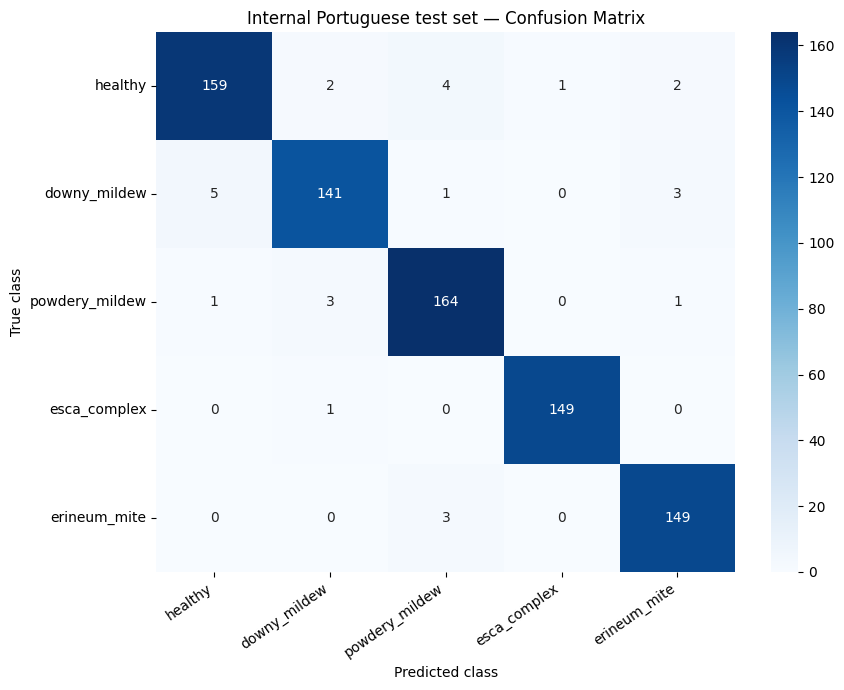

NameError: name 'external_field_test_loader' is not defined

In [35]:
from pathlib import Path
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)
BEST_CHECKPOINT = EXPERIMENT_DIR / "grape_best_model.pth"

if not BEST_CHECKPOINT.exists():
    raise FileNotFoundError(f"Best checkpoint not found: {BEST_CHECKPOINT}")

# Load the best model weights
checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False,
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded best checkpoint")
print("Best epoch:", checkpoint.get("epoch", "not recorded"))
print("Best validation macro-F1:", round(checkpoint.get("best_val_f1", float("nan")), 4))
print("Classes:", CLASS_NAMES)


def evaluate_test_set(loader, split_name):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for full_images, tile_images, targets in loader:
            full_images = full_images.to(DEVICE, non_blocking=True)
            tile_images = tile_images.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = model(full_images, tile_images)

            y_true.extend(targets.tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().tolist())

    label_ids = list(range(len(CLASS_NAMES)))

    print(f"\n{'=' * 70}")
    print(split_name)
    print(f"{'=' * 70}")
    print(f"Images: {len(y_true)}")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(f"Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}")
    print(
        f"Macro-F1: "
        f"{f1_score(y_true, y_pred, labels=label_ids, average='macro', zero_division=0):.4f}"
    )

    print("\nPer-class report:")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=label_ids,
            target_names=CLASS_NAMES,
            zero_division=0,
            digits=4,
        )
    )

    matrix = confusion_matrix(y_true, y_pred, labels=label_ids)
    matrix_df = pd.DataFrame(
        matrix,
        index=CLASS_NAMES,
        columns=CLASS_NAMES,
    )

    plt.figure(figsize=(9, 7))
    sns.heatmap(matrix_df, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{split_name} — Confusion Matrix")
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.xticks(rotation=35, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return y_true, y_pred, matrix_df


internal_results = evaluate_test_set(
    internal_test_loader,
    "Internal Portuguese test set",
)

external_results = evaluate_test_set(
    external_field_test_loader,
    "External FieldVitis test set",
)

In [37]:
external_test_df = pd.read_csv(EXPERIMENT_DIR / "external_field_test_manifest.csv")

external_test_dataset = GrapeDataset(
    external_test_df,
    class_to_idx=CLASS_TO_IDX,
    image_size=448,
    tile_size=288,
    training=False,
)

external_field_test_loader = DataLoader(
    external_test_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

print("External FieldVitis test images:", len(external_test_dataset))
print(external_test_df.groupby("label").size())

NameError: name 'GrapeDataset' is not defined


External FieldVitis test set
Images: 358
Accuracy: 0.4302
Balanced accuracy: 0.4116
Macro-F1: 0.2089

Per-class report:
                precision    recall  f1-score   support

       healthy     0.7143    0.2532    0.3738       158
  downy_mildew     0.0000    0.0000    0.0000         0
powdery_mildew     0.0000    0.0000    0.0000         0
  esca_complex     0.8143    0.5700    0.6706       200
  erineum_mite     0.0000    0.0000    0.0000         0

      accuracy                         0.4302       358
     macro avg     0.3057    0.1646    0.2089       358
  weighted avg     0.7702    0.4302    0.5396       358



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


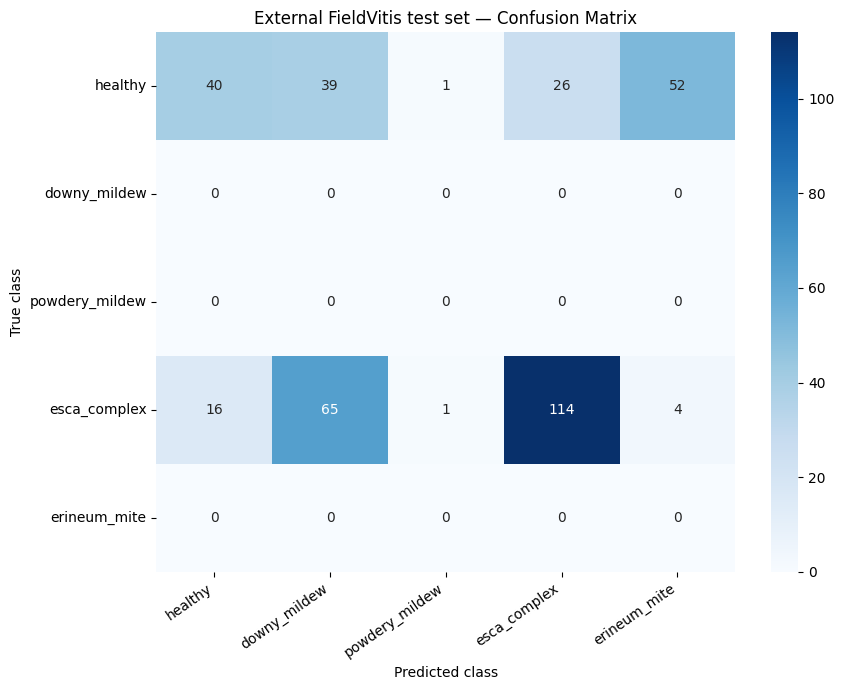

External FieldVitis test images: 358
label
esca_complex    200
healthy         158
dtype: int64


In [41]:
from pathlib import Path
from torch.utils.data import DataLoader

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)
external_manifest_path = EXPERIMENT_DIR / "external_field_test_manifest.csv"

external_test_df = pd.read_csv(external_manifest_path)

external_results = evaluate_test_set(
    external_field_test_loader,
    "External FieldVitis test set",
)


external_field_test_loader = DataLoader(
    external_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

print("External FieldVitis test images:", len(external_test_dataset))
print(external_test_df.groupby("label").size())

In [38]:
print("Dataset class:", type(internal_test_loader.dataset).__name__)
print("Dataset settings:", vars(internal_test_loader.dataset))

Dataset class: GrapeImageDataset
Dataset settings: {'dataframe':                                             image_path           label  \
0    /content/grape_raw/Resized 1024 × 1024/resized...         healthy   
1    /content/grape_raw/Resized 1024 × 1024/resized...    erineum_mite   
2    /content/grape_raw/Resized 1024 × 1024/resized...         healthy   
3    /content/grape_raw/Resized 1024 × 1024/resized...  powdery_mildew   
4    /content/grape_raw/Resized 1024 × 1024/resized...    erineum_mite   
..                                                 ...             ...   
784  /content/grape_raw/Resized 1024 × 1024/resized...         healthy   
785  /content/grape_raw/Resized 1024 × 1024/resized...  powdery_mildew   
786  /content/grape_raw/Resized 1024 × 1024/resized...    esca_complex   
787  /content/grape_raw/Resized 1024 × 1024/resized...    downy_mildew   
788  /content/grape_raw/Resized 1024 × 1024/resized...    erineum_mite   

             source  target  
0    portuguese_

In [39]:
from pathlib import Path
from torch.utils.data import DataLoader
import pandas as pd

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)

external_test_df = pd.read_csv(
    EXPERIMENT_DIR / "external_field_test_manifest.csv"
)

external_test_dataset = GrapeImageDataset(
    external_test_df,
    training=False,
)

external_field_test_loader = DataLoader(
    external_test_dataset,
    batch_size=internal_test_loader.batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

print("External FieldVitis images:", len(external_test_dataset))
print(external_test_df.groupby("label").size())
print("Class-index mapping:")
print(dict(zip(CLASS_NAMES, range(len(CLASS_NAMES)))))

External FieldVitis images: 358
label
esca_complex    200
healthy         158
dtype: int64
Class-index mapping:
{'healthy': 0, 'downy_mildew': 1, 'powdery_mildew': 2, 'esca_complex': 3, 'erineum_mite': 4}


In [42]:
import random
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Unpack results from the external evaluation
y_true, y_pred, confusion_df = external_results

print("External confusion matrix:")
display(confusion_df)

# Show only classes that actually occur in this test set
present_class_ids = sorted(set(y_true))
present_classes = [CLASS_NAMES[i] for i in present_class_ids]

print("\nConfusion matrix for the two true FieldVitis classes:")
display(
    pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=present_class_ids),
        index=present_classes,
        columns=present_classes,
    )
)

# Add true and predicted names to the FieldVitis manifest
external_review_df = external_test_df.copy().reset_index(drop=True)
external_review_df["true_label"] = [
    CLASS_NAMES[i] for i in y_true
]
external_review_df["predicted_label"] = [
    CLASS_NAMES[i] for i in y_pred
]
external_review_df["correct"] = (
    external_review_df["true_label"] == external_review_df["predicted_label"]
)

print("\nCorrect predictions:", int(external_review_df["correct"].sum()))
print("Incorrect predictions:", int((~external_review_df["correct"]).sum()))

# Display a random sample of up to 12 errors
errors = external_review_df[~external_review_df["correct"]]
sample_count = min(12, len(errors))

if sample_count:
    sample_errors = errors.sample(sample_count, random_state=42)

    fig, axes = plt.subplots(
        nrows=(sample_count + 3) // 4,
        ncols=4,
        figsize=(16, 4 * ((sample_count + 3) // 4)),
    )
    axes = axes.flatten()

    for ax, (_, row) in zip(axes, sample_errors.iterrows()):
        try:
            image = Image.open(row["image_path"]).convert("RGB")
            ax.imshow(image)
            ax.set_title(
                f"True: {row['true_label']}\nPred: {row['predicted_label']}",
                fontsize=10,
            )
        except Exception as exc:
            ax.text(0.05, 0.5, f"Could not open image:\n{exc}", fontsize=8)

        ax.axis("off")

    for ax in axes[sample_count:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No external-test errors to display.")

Output hidden; open in https://colab.research.google.com to view.

In [43]:
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

# Show up to 8 correct and 12 incorrect examples
correct_rows = external_review_df[external_review_df["correct"]]
error_rows = external_review_df[~external_review_df["correct"]]

sample_correct = correct_rows.sample(
    min(8, len(correct_rows)), random_state=7
)
sample_errors = error_rows.sample(
    min(12, len(error_rows)), random_state=7
)

review_rows = pd.concat([sample_correct, sample_errors]).reset_index(drop=True)

fig, axes = plt.subplots(5, 4, figsize=(16, 18))
axes = axes.flatten()

for ax, (_, row) in zip(axes, review_rows.iterrows()):
    try:
        image = Image.open(row["image_path"]).convert("RGB")
        ax.imshow(image)
        ax.set_title(
            f"True: {row['true_label']}\n"
            f"Pred: {row['predicted_label']}",
            fontsize=9,
        )
    except Exception as exc:
        ax.text(0.05, 0.5, f"Image read error:\n{exc}", fontsize=8)

    ax.axis("off")

for ax in axes[len(review_rows):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [44]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)

field_df = pd.read_csv(EXPERIMENT_DIR / "external_field_test_manifest.csv")

# Keep the two field classes that match this model.
field_df = field_df[field_df["label"].isin(["healthy", "esca_complex"])].copy()

# Split within each class so both sets contain Healthy and Esca.
field_train_df, field_val_df = train_test_split(
    field_df,
    test_size=0.25,
    random_state=42,
    stratify=field_df["label"],
)

field_train_df = field_train_df.reset_index(drop=True)
field_val_df = field_val_df.reset_index(drop=True)

field_train_path = EXPERIMENT_DIR / "field_adaptation_train_manifest.csv"
field_val_path = EXPERIMENT_DIR / "field_adaptation_val_manifest.csv"

field_train_df.to_csv(field_train_path, index=False)
field_val_df.to_csv(field_val_path, index=False)

print("Field adaptation train images:", len(field_train_df))
print(field_train_df.groupby("label").size())
print("\nField adaptation validation images:", len(field_val_df))
print(field_val_df.groupby("label").size())
print("\nSaved:")
print(field_train_path)
print(field_val_path)

Field adaptation train images: 268
label
esca_complex    150
healthy         118
dtype: int64

Field adaptation validation images: 90
label
esca_complex    50
healthy         40
dtype: int64

Saved:
/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/field_adaptation_train_manifest.csv
/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/field_adaptation_val_manifest.csv


In [45]:
from pathlib import Path
import pandas as pd
from torch.utils.data import ConcatDataset, DataLoader

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)

# Load the existing Portuguese training manifest and new FieldVitis split.
portuguese_train_df = pd.read_csv(EXPERIMENT_DIR / "train_manifest.csv")
field_train_df = pd.read_csv(EXPERIMENT_DIR / "field_adaptation_train_manifest.csv")
field_val_df = pd.read_csv(EXPERIMENT_DIR / "field_adaptation_val_manifest.csv")

# The manifests include the target indices used by the model.
print("Portuguese training columns:", portuguese_train_df.columns.tolist())
print("Field training columns:", field_train_df.columns.tolist())

# Ensure all rows use the model's established class mapping.
label_to_target = {
    name: index for index, name in enumerate(CLASS_NAMES)
}
for dataframe in (portuguese_train_df, field_train_df, field_val_df):
    dataframe["target"] = dataframe["label"].map(label_to_target)

if any(dataframe["target"].isna().any()
       for dataframe in (portuguese_train_df, field_train_df, field_val_df)):
    raise ValueError("A manifest contains a label not present in CLASS_NAMES.")

# Use the existing dataset class. Training augmentation is enabled only
# for the training datasets; validation uses deterministic preprocessing.
portuguese_train_dataset = GrapeImageDataset(
    portuguese_train_df,
    training=True,
)
field_train_dataset = GrapeImageDataset(
    field_train_df,
    training=True,
)
field_val_dataset = GrapeImageDataset(
    field_val_df,
    training=False,
)

# Mix Portuguese and FieldVitis training images in the same loader.
adaptation_train_dataset = ConcatDataset(
    [portuguese_train_dataset, field_train_dataset]
)

# Reuse the batch size from the original training loader.
adaptation_batch_size = train_loader.batch_size

adaptation_train_loader = DataLoader(
    adaptation_train_dataset,
    batch_size=adaptation_batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

field_adaptation_val_loader = DataLoader(
    field_val_dataset,
    batch_size=adaptation_batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

print("\nPortuguese training images:", len(portuguese_train_dataset))
print("FieldVitis adaptation images:", len(field_train_dataset))
print("Combined adaptation training images:", len(adaptation_train_dataset))
print("FieldVitis validation images:", len(field_val_dataset))
print("Training batch size:", adaptation_batch_size)

Portuguese training columns: ['image_path', 'label', 'source', 'target']
Field training columns: ['image_path', 'label', 'source', 'target']

Portuguese training images: 3678
FieldVitis adaptation images: 268
Combined adaptation training images: 3946
FieldVitis validation images: 90
Training batch size: 2


In [46]:
import copy
import torch

BEST_CHECKPOINT = (
    EXPERIMENT_DIR / "grape_best_model.pth"
)

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False,
)

# Make a separate copy; do not modify the baseline model.
adapted_model = copy.deepcopy(model)
adapted_model.load_state_dict(checkpoint["model_state_dict"])
adapted_model.to(DEVICE)

# Freeze the whole model first.
for parameter in adapted_model.parameters():
    parameter.requires_grad = False

# Unfreeze the classifier/head and the final ResNet stage.
# These names match the model definition used in the earlier pipeline.
for name, parameter in adapted_model.named_parameters():
    if any(key in name for key in ["layer4", "classifier", "head", "attention", "fusion"]):
        parameter.requires_grad = True

trainable_parameters = sum(
    parameter.numel()
    for parameter in adapted_model.parameters()
    if parameter.requires_grad
)
total_parameters = sum(
    parameter.numel()
    for parameter in adapted_model.parameters()
)

print("Loaded baseline checkpoint from epoch:", checkpoint.get("epoch"))
print("Baseline validation macro-F1:", checkpoint.get("best_val_f1"))
print(f"Trainable parameters: {trainable_parameters:,} / {total_parameters:,}")
print("Original model remains unchanged.")

Loaded baseline checkpoint from epoch: 10
Baseline validation macro-F1: 0.9646754128311621
Trainable parameters: 17,527,813 / 26,989,638
Original model remains unchanged.


In [47]:
# Freeze all parameters first
for parameter in adapted_model.parameters():
    parameter.requires_grad = False

# Unfreeze only ResNet layer4 and the final classifier
for name, parameter in adapted_model.named_parameters():
    if name.startswith("backbone.layer4.") or name.startswith("classifier."):
        parameter.requires_grad = True

trainable_parameters = sum(
    parameter.numel()
    for parameter in adapted_model.parameters()
    if parameter.requires_grad
)
total_parameters = sum(
    parameter.numel()
    for parameter in adapted_model.parameters()
)

print(f"Trainable parameters: {trainable_parameters:,} / {total_parameters:,}")
print("Trainable sections:")
for name, parameter in adapted_model.named_parameters():
    if parameter.requires_grad:
        print(" ", name)


Trainable parameters: 397,829 / 26,989,638
Trainable sections:
  classifier.0.weight
  classifier.0.bias
  classifier.2.weight
  classifier.2.bias
  classifier.5.weight
  classifier.5.bias


In [48]:
for name, parameter in adapted_model.named_parameters():
    if "layer4" in name or name.endswith("weight") and ("classifier" in name or "head" in name):
        print(name, tuple(parameter.shape))

layer4.0.conv1.weight (512, 1024, 1, 1)
layer4.0.bn1.weight (512,)
layer4.0.bn1.bias (512,)
layer4.0.conv2.weight (512, 512, 3, 3)
layer4.0.bn2.weight (512,)
layer4.0.bn2.bias (512,)
layer4.0.conv3.weight (2048, 512, 1, 1)
layer4.0.bn3.weight (2048,)
layer4.0.bn3.bias (2048,)
layer4.0.downsample.0.weight (2048, 1024, 1, 1)
layer4.0.downsample.1.weight (2048,)
layer4.0.downsample.1.bias (2048,)
layer4.1.conv1.weight (512, 2048, 1, 1)
layer4.1.bn1.weight (512,)
layer4.1.bn1.bias (512,)
layer4.1.conv2.weight (512, 512, 3, 3)
layer4.1.bn2.weight (512,)
layer4.1.bn2.bias (512,)
layer4.1.conv3.weight (2048, 512, 1, 1)
layer4.1.bn3.weight (2048,)
layer4.1.bn3.bias (2048,)
layer4.2.conv1.weight (512, 2048, 1, 1)
layer4.2.bn1.weight (512,)
layer4.2.bn1.bias (512,)
layer4.2.conv2.weight (512, 512, 3, 3)
layer4.2.bn2.weight (512,)
layer4.2.bn2.bias (512,)
layer4.2.conv3.weight (2048, 512, 1, 1)
layer4.2.bn3.weight (2048,)
layer4.2.bn3.bias (2048,)
classifier.0.weight (768,)
classifier.2.weight (5

In [49]:
# Keep everything frozen, then unfreeze layer4 and the classifier.
for parameter in adapted_model.parameters():
    parameter.requires_grad = False

for name, parameter in adapted_model.named_parameters():
    if name.startswith("layer4.") or name.startswith("classifier."):
        parameter.requires_grad = True

trainable_parameters = sum(
    parameter.numel()
    for parameter in adapted_model.parameters()
    if parameter.requires_grad
)

print(f"Trainable parameters: {trainable_parameters:,}")
print("Trainable sections:", sorted({
    name.split(".")[0]
    for name, parameter in adapted_model.named_parameters()
    if parameter.requires_grad
}))

Trainable parameters: 15,362,565
Trainable sections: ['classifier', 'layer4']


In [50]:
import torch
from pathlib import Path

# Freeze the entire model, then train only the classifier.
for parameter in adapted_model.parameters():
    parameter.requires_grad = False

for parameter in adapted_model.classifier.parameters():
    parameter.requires_grad = True

# Classifier-only fine-tuning with a low learning rate.
adaptation_optimizer = torch.optim.AdamW(
    adapted_model.classifier.parameters(),
    lr=1e-5,
    weight_decay=1e-3,
)

adaptation_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    adaptation_optimizer,
    mode="max",
    factor=0.5,
    patience=1,
)

adaptation_best_path = EXPERIMENT_DIR / "grape_field_adapted_best.pth"
adaptation_last_path = EXPERIMENT_DIR / "grape_field_adapted_last.pth"

print("Trainable parameters:", sum(
    p.numel() for p in adapted_model.parameters() if p.requires_grad
))
print("Best adaptation checkpoint:", adaptation_best_path)
print("Latest adaptation checkpoint:", adaptation_last_path)

Trainable parameters: 397829
Best adaptation checkpoint: /content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/grape_field_adapted_best.pth
Latest adaptation checkpoint: /content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/grape_field_adapted_last.pth


In [51]:
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, balanced_accuracy_score
import numpy as np
import torch

ADAPTATION_EPOCHS = 8
ADAPTATION_PATIENCE = 3

adaptation_best_f1 = -1.0
adaptation_bad_epochs = 0

def evaluate_adaptation(loader):
    adapted_model.eval()
    true_labels = []
    predicted_labels = []
    total_loss = 0.0

    with torch.no_grad():
        for full_images, tile_images, targets in loader:
            full_images = full_images.to(DEVICE, non_blocking=True)
            tile_images = tile_images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = adapted_model(full_images, tile_images)
                loss = criterion(logits, targets)

            total_loss += loss.item() * targets.size(0)
            true_labels.extend(targets.cpu().tolist())
            predicted_labels.extend(logits.argmax(dim=1).cpu().tolist())

    macro_f1 = f1_score(
        true_labels,
        predicted_labels,
        labels=list(range(len(CLASS_NAMES))),
        average="macro",
        zero_division=0,
    )
    balanced_acc = balanced_accuracy_score(true_labels, predicted_labels)

    return total_loss / len(loader.dataset), macro_f1, balanced_acc


for epoch in range(1, ADAPTATION_EPOCHS + 1):
    adapted_model.train()
    total_train_loss = 0.0
    train_true = []
    train_pred = []

    progress = tqdm(
        adaptation_train_loader,
        desc=f"Field adaptation epoch {epoch}/{ADAPTATION_EPOCHS}",
    )

    for full_images, tile_images, targets in progress:
        full_images = full_images.to(DEVICE, non_blocking=True)
        tile_images = tile_images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        adaptation_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            logits = adapted_model(full_images, tile_images)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.unscale_(adaptation_optimizer)
        torch.nn.utils.clip_grad_norm_(
            adapted_model.classifier.parameters(),
            max_norm=1.0,
        )
        scaler.step(adaptation_optimizer)
        scaler.update()

        total_train_loss += loss.item() * targets.size(0)
        train_true.extend(targets.detach().cpu().tolist())
        train_pred.extend(logits.argmax(dim=1).detach().cpu().tolist())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = total_train_loss / len(adaptation_train_loader.dataset)
    train_f1 = f1_score(
        train_true,
        train_pred,
        labels=list(range(len(CLASS_NAMES))),
        average="macro",
        zero_division=0,
    )

    val_loss, val_f1, val_balanced_acc = evaluate_adaptation(
        field_adaptation_val_loader
    )
    adaptation_scheduler.step(val_f1)

    print(
        f"\nEpoch {epoch} | "
        f"Train loss: {train_loss:.4f}, Train macro-F1: {train_f1:.4f} | "
        f"Field val loss: {val_loss:.4f}, Field val macro-F1: {val_f1:.4f}, "
        f"Field val balanced accuracy: {val_balanced_acc:.4f}"
    )

    if val_f1 > adaptation_best_f1:
        adaptation_best_f1 = val_f1
        adaptation_bad_epochs = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": adapted_model.state_dict(),
                "class_names": CLASS_NAMES,
                "field_val_macro_f1": val_f1,
                "field_val_balanced_accuracy": val_balanced_acc,
            },
            adaptation_best_path,
        )
        print("Saved new best field-adapted checkpoint.")
    else:
        adaptation_bad_epochs += 1

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": adapted_model.state_dict(),
            "optimizer_state_dict": adaptation_optimizer.state_dict(),
            "scheduler_state_dict": adaptation_scheduler.state_dict(),
            "best_field_val_f1": adaptation_best_f1,
            "bad_epochs": adaptation_bad_epochs,
            "class_names": CLASS_NAMES,
        },
        adaptation_last_path,
    )

    if adaptation_bad_epochs >= ADAPTATION_PATIENCE:
        print("Early stopping: field validation macro-F1 did not improve.")
        break

print("\nBest FieldVitis development macro-F1:", round(adaptation_best_f1, 4))
print("Best adapted checkpoint:", adaptation_best_path)

Field adaptation epoch 1/8:   0%|          | 0/1973 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")



Epoch 1 | Train loss: 0.1298, Train macro-F1: 0.9569 | Field val loss: 0.8016, Field val macro-F1: 0.2489, Field val balanced accuracy: 0.6300
Saved new best field-adapted checkpoint.


Field adaptation epoch 2/8:   0%|          | 0/1973 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [52]:
from pathlib import Path
import torch

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)
LAST_ADAPTATION = EXPERIMENT_DIR / "grape_field_adapted_last.pth"
BEST_ADAPTATION = EXPERIMENT_DIR / "grape_field_adapted_best.pth"

if LAST_ADAPTATION.exists():
    last = torch.load(LAST_ADAPTATION, map_location="cpu", weights_only=False)
    print("Latest completed adaptation epoch:", last["epoch"])
else:
    print("No completed adaptation checkpoint exists.")

if BEST_ADAPTATION.exists():
    best = torch.load(BEST_ADAPTATION, map_location="cpu", weights_only=False)
    print("Best adaptation epoch:", best["epoch"])
    print("Best FieldVitis validation macro-F1:", best["field_val_macro_f1"])

Latest completed adaptation epoch: 1
Best adaptation epoch: 1
Best FieldVitis validation macro-F1: 0.24888888888888888


In [54]:
import torch
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, balanced_accuracy_score

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)
BEST_ADAPTATION = EXPERIMENT_DIR / "grape_field_adapted_best.pth"
LAST_ADAPTATION = EXPERIMENT_DIR / "grape_field_adapted_last.pth"
ADAPTATION_HISTORY = EXPERIMENT_DIR / "grape_field_adaptation_history.csv"

# Restore the last fully completed epoch (Epoch 1).
checkpoint = torch.load(
    LAST_ADAPTATION,
    map_location=DEVICE,
    weights_only=False,
)
adapted_model.load_state_dict(checkpoint["model_state_dict"])
adaptation_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
adaptation_scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

start_epoch = checkpoint["epoch"] + 1
adaptation_best_f1 = checkpoint["best_field_val_f1"]
adaptation_bad_epochs = checkpoint["bad_epochs"]
adaptation_history = checkpoint.get("history", [])

print(f"Resuming from adaptation epoch {start_epoch}")
print(f"Best FieldVitis validation macro-F1 so far: {adaptation_best_f1:.4f}")


def evaluate_adaptation(loader):
    adapted_model.eval()
    total_loss = 0.0
    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for full_images, tile_images, targets in loader:
            full_images = full_images.to(DEVICE, non_blocking=True)
            tile_images = tile_images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = adapted_model(full_images, tile_images)
                loss = criterion(logits, targets)

            total_loss += loss.item() * targets.size(0)
            true_labels.extend(targets.cpu().tolist())
            predicted_labels.extend(logits.argmax(dim=1).cpu().tolist())

    macro_f1 = f1_score(
        true_labels,
        predicted_labels,
        labels=list(range(len(CLASS_NAMES))),
        average="macro",
        zero_division=0,
    )
    balanced_acc = balanced_accuracy_score(true_labels, predicted_labels)

    return total_loss / len(loader.dataset), macro_f1, balanced_acc


for epoch in range(start_epoch, ADAPTATION_EPOCHS + 1):
    adapted_model.train()
    total_train_loss = 0.0
    train_true = []
    train_pred = []

    progress = tqdm(
        adaptation_train_loader,
        desc=f"Field adaptation epoch {epoch}/{ADAPTATION_EPOCHS}",
    )

    for full_images, tile_images, targets in progress:
        full_images = full_images.to(DEVICE, non_blocking=True)
        tile_images = tile_images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        adaptation_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            logits = adapted_model(full_images, tile_images)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.unscale_(adaptation_optimizer)
        torch.nn.utils.clip_grad_norm_(
            adapted_model.classifier.parameters(),
            max_norm=1.0,
        )
        scaler.step(adaptation_optimizer)
        scaler.update()

        total_train_loss += loss.item() * targets.size(0)
        train_true.extend(targets.detach().cpu().tolist())
        train_pred.extend(logits.argmax(dim=1).detach().cpu().tolist())
        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = total_train_loss / len(adaptation_train_loader.dataset)
    train_f1 = f1_score(
        train_true,
        train_pred,
        labels=list(range(len(CLASS_NAMES))),
        average="macro",
        zero_division=0,
    )

    val_loss, val_f1, val_balanced_acc = evaluate_adaptation(
        field_adaptation_val_loader
    )
    adaptation_scheduler.step(val_f1)

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_macro_f1": train_f1,
        "field_val_loss": val_loss,
        "field_val_macro_f1": val_f1,
        "field_val_balanced_accuracy": val_balanced_acc,
    }
    adaptation_history.append(record)
    pd.DataFrame(adaptation_history).to_csv(ADAPTATION_HISTORY, index=False)

    print(
        f"\nEpoch {epoch} | "
        f"Train loss: {train_loss:.4f}, Train macro-F1: {train_f1:.4f} | "
        f"Field val loss: {val_loss:.4f}, Field val macro-F1: {val_f1:.4f}, "
        f"Field val balanced accuracy: {val_balanced_acc:.4f}"
    )

    if val_f1 > adaptation_best_f1:
        adaptation_best_f1 = val_f1
        adaptation_bad_epochs = 0
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": adapted_model.state_dict(),
                "class_names": CLASS_NAMES,
                "field_val_macro_f1": val_f1,
                "field_val_balanced_accuracy": val_balanced_acc,
            },
            BEST_ADAPTATION,
        )
        print("Saved new best adaptation checkpoint.")
    else:
        adaptation_bad_epochs += 1

    # Save the last completed epoch for reliable resuming.
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": adapted_model.state_dict(),
            "optimizer_state_dict": adaptation_optimizer.state_dict(),
            "scheduler_state_dict": adaptation_scheduler.state_dict(),
            "best_field_val_f1": adaptation_best_f1,
            "bad_epochs": adaptation_bad_epochs,
            "history": adaptation_history,
            "class_names": CLASS_NAMES,
        },
        LAST_ADAPTATION,
    )
    print("Saved latest adaptation checkpoint.")

    if adaptation_bad_epochs >= ADAPTATION_PATIENCE:
        print("Early stopping: field validation macro-F1 did not improve.")
        break

print(f"\nBest field validation macro-F1: {adaptation_best_f1:.4f}")
print("Best adapted checkpoint:", BEST_ADAPTATION)

Resuming from adaptation epoch 2
Best FieldVitis validation macro-F1 so far: 0.2489


Field adaptation epoch 2/8:   0%|          | 0/1973 [00:00<?, ?it/s]

KeyboardInterrupt: 